In [3]:
import pandas as pd

### TABLICA 9

In [ ]:
df9 = pd.read_csv(
    "tablica_9_broj-erasmus-zaprimljenih-i-odobrenih-projekata-2021_2027.csv",
    sep=";",
    skiprows=2,
    encoding="utf-8"
)

df9

,Natječajna godina,Unnamed: 1,Unnamed: 2,Unnamed: 3,Odgoj i opće obrazovanje,Strukovno obrazovanje i osposobljavanje,Visoko obrazovanje,Obrazovanje odraslih,Mladi,Sport,Ukupno prema natječajnoj godini
0,2021.,NaN,KA1,Prijave,84,50,38,19,122,NaN,313
1,NaN,NaN,NaN,Ugovoreni,71,48,38,17,55,NaN,229
2,NaN,NaN,NaN,% prolaznosti,"84,5%","96,0%","100,0%","89,5%","45,1%",NaN,"73,2%"
3,NaN,NaN,KA2,Prijave,56,40,15,53,68,NaN,232
4,NaN,NaN,NaN,Ugovoreni,22,15,5,13,22,NaN,77
5,NaN,NaN,NaN,% prolaznosti,"39,3%","37,5%","33,3%","24,5%","32,4%",NaN,"33,2%"
6,2022.,NaN,KA1,Prijave,147,94,67,35,148,NaN,491
7,NaN,NaN,NaN,Ugovoreni,121,70,63,28,74,NaN,356
8,NaN,NaN,NaN,% prolaznosti,"82,3%","74,5%","94,0%","80,0%","50,0%",NaN,"72,5%"
9,NaN,NaN,KA2,Prijave,85,32,20,53,77,NaN,267


In [ ]:
df9.style.format(precision=1, na_rep="")

,Natječajna godina,Unnamed: 1,Unnamed: 2,Unnamed: 3,Odgoj i opće obrazovanje,Strukovno obrazovanje i osposobljavanje,Visoko obrazovanje,Obrazovanje odraslih,Mladi,Sport,Ukupno prema natječajnoj godini
0,2021.,,KA1,Prijave,84,50,38,19,122,,313
1,,,,Ugovoreni,71,48,38,17,55,,229
2,,,,% prolaznosti,"84,5%","96,0%","100,0%","89,5%","45,1%",,"73,2%"
3,,,KA2,Prijave,56,40,15,53,68,,232
4,,,,Ugovoreni,22,15,5,13,22,,77
5,,,,% prolaznosti,"39,3%","37,5%","33,3%","24,5%","32,4%",,"33,2%"
6,2022.,,KA1,Prijave,147,94,67,35,148,,491
7,,,,Ugovoreni,121,70,63,28,74,,356
8,,,,% prolaznosti,"82,3%","74,5%","94,0%","80,0%","50,0%",,"72,5%"
9,,,KA2,Prijave,85,32,20,53,77,,267


In [ ]:
df9.columns = [
    "godina",                 # Natječajna godina
    "prazno_1",               # prazan stupac
    "kljucna_akcija",         # KA1 / KA2
    "vrsta",                  # Prijave / Ugovoreni / % prolaznosti
    "odgoj_i_opce_obrazovanje",
    "strukovno_obrazovanje",
    "visoko_obrazovanje",
    "obrazovanje_odraslih",
    "mladi",
    "sport",
    "ukupno"
]

df9.head(10)

,godina,prazno_1,kljucna_akcija,vrsta,odgoj_i_opce_obrazovanje,strukovno_obrazovanje,visoko_obrazovanje,obrazovanje_odraslih,mladi,sport,ukupno
0,2021.,NaN,KA1,Prijave,84,50,38,19,122,NaN,313
1,NaN,NaN,NaN,Ugovoreni,71,48,38,17,55,NaN,229
2,NaN,NaN,NaN,% prolaznosti,"84,5%","96,0%","100,0%","89,5%","45,1%",NaN,"73,2%"
3,NaN,NaN,KA2,Prijave,56,40,15,53,68,NaN,232
4,NaN,NaN,NaN,Ugovoreni,22,15,5,13,22,NaN,77
5,NaN,NaN,NaN,% prolaznosti,"39,3%","37,5%","33,3%","24,5%","32,4%",NaN,"33,2%"
6,2022.,NaN,KA1,Prijave,147,94,67,35,148,NaN,491
7,NaN,NaN,NaN,Ugovoreni,121,70,63,28,74,NaN,356
8,NaN,NaN,NaN,% prolaznosti,"82,3%","74,5%","94,0%","80,0%","50,0%",NaN,"72,5%"
9,NaN,NaN,KA2,Prijave,85,32,20,53,77,NaN,267


In [ ]:
df9["godina"] = df9["godina"].ffill()
df9["kljucna_akcija"] = df9["kljucna_akcija"].ffill()

df9 = df9.drop(columns="prazno_1")

df9["vrsta"] = df9["vrsta"].str.strip()

df9.head(12)

,godina,kljucna_akcija,vrsta,odgoj_i_opce_obrazovanje,strukovno_obrazovanje,visoko_obrazovanje,obrazovanje_odraslih,mladi,sport,ukupno
0,2021.,KA1,Prijave,84,50,38,19,122,NaN,313
1,2021.,KA1,Ugovoreni,71,48,38,17,55,NaN,229
2,2021.,KA1,% prolaznosti,"84,5%","96,0%","100,0%","89,5%","45,1%",NaN,"73,2%"
3,2021.,KA2,Prijave,56,40,15,53,68,NaN,232
4,2021.,KA2,Ugovoreni,22,15,5,13,22,NaN,77
5,2021.,KA2,% prolaznosti,"39,3%","37,5%","33,3%","24,5%","32,4%",NaN,"33,2%"
6,2022.,KA1,Prijave,147,94,67,35,148,NaN,491
7,2022.,KA1,Ugovoreni,121,70,63,28,74,NaN,356
8,2022.,KA1,% prolaznosti,"82,3%","74,5%","94,0%","80,0%","50,0%",NaN,"72,5%"
9,2022.,KA2,Prijave,85,32,20,53,77,NaN,267


In [ ]:
# zadrži samo godišnje retke, bez "Sveukupno..."
df9 = df9[df9["godina"].str.match(r"^\d{4}\.$")]

# zadrži samo prijave i ugovorene, bez "% prolaznosti"
ukupno = df9[df9["vrsta"].isin(["Prijave", "Ugovoreni"])].copy()

# pretvori brojeve u numeric
ukupno["ukupno"] = pd.to_numeric(ukupno["ukupno"], errors="coerce")

pivot9 = ukupno.pivot_table(
    index="godina",
    columns="vrsta",
    values="ukupno",
    aggfunc="sum"
)

pivot9["prolaznost_%"] = (
    pivot9["Ugovoreni"] / pivot9["Prijave"] * 100
).round(1)

pivot9

vrsta,Prijave,Ugovoreni,prolaznost_%
godina,,,
2021.,545,306,56.1
2022.,758,410,54.1
2023.,1111,520,46.8
2024.,1322,575,43.5
2025.,1261,642,50.9
2026.,1252,640,51.1


In [9]:
import matplotlib.pyplot as plt

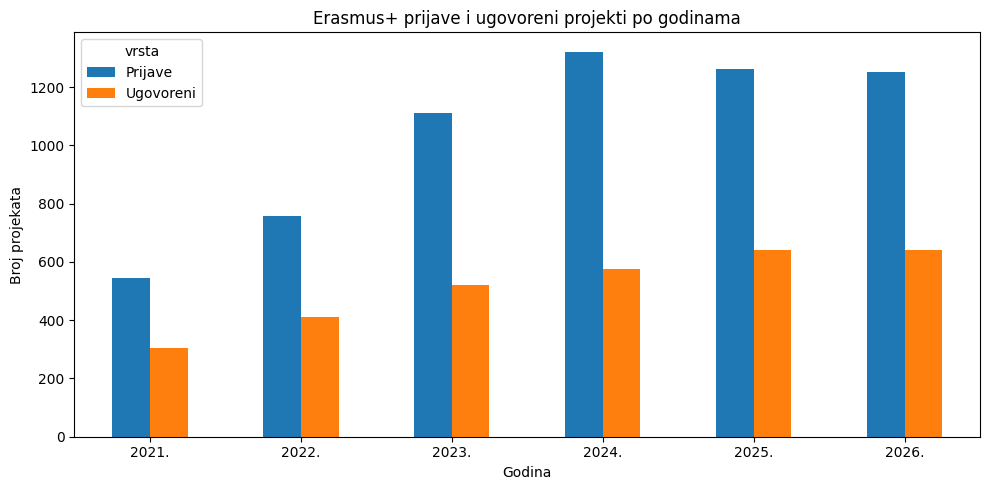

In [ ]:
pivot9[["Prijave", "Ugovoreni"]].plot(
    kind="bar",
    figsize=(10, 5),
    title="Erasmus+ prijave i ugovoreni projekti po godinama"
)

plt.ylabel("Broj projekata")
plt.xlabel("Godina")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

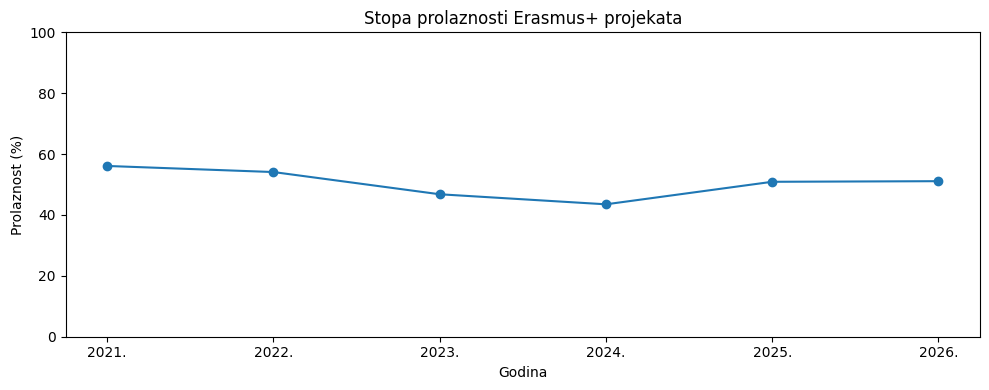

In [ ]:
pivot9["prolaznost_%"].plot(
    kind="line",
    marker="o",
    figsize=(10, 4),
    title="Stopa prolaznosti Erasmus+ projekata"
)

plt.ylabel("Prolaznost (%)")
plt.xlabel("Godina")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

### TABLICA 8

In [31]:
df8 = pd.read_csv(
    "tablica_8_pregled-financijskih-rezultata-programa-erasmus-2021_2027.csv",
    sep=";",
    skiprows=2,
    encoding="utf-8-sig"
)

df8.head()

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12
0,Natječajna godina,NaN,Stavka,Odgoj i opće obrazovanje,Strukovno obrazovanje i osposobljavanje,Visoko obrazovanje,Obrazovanje odraslih,Mladi,Sport*,Ukupno,NaN,NaN,NaN
1,2021.\n,NaN,Raspoloživo,"4.675.459,00 EUR","6.017.449,00 EUR","10.444.803,00 EUR","1.849.024,00 EUR","4.975.755,00 EUR",NaN,"27.962.490,00 EUR",NaN,NaN,NaN
2,NaN,NaN,Ugovoreno,"4.493.838,40 EUR","5.964.251,93 EUR","10.092.072,00 EUR","1.807.901,80 EUR","4.825.077,00 EUR",NaN,"27.183.141,13 EUR",NaN,NaN,NaN
3,NaN,NaN,Realizirano,"4.322.765,26 EUR","5.801.464,60 EUR","9.324.177,78 EUR","1.763.380,00 EUR","4.509.019,60 EUR",NaN,"25.720.807,24 EUR",NaN,NaN,NaN
4,NaN,NaN,% ugovorenih sredstava,"96,1%","99,1%","96,6%","97,8%","97,0%",NaN,"97,2%",NaN,NaN,NaN


In [32]:
df8.columns = [
    "godina", "prazno_1", "stavka",
    "odgoj_i_opce_obrazovanje",
    "strukovno_obrazovanje",
    "visoko_obrazovanje",
    "obrazovanje_odraslih",
    "mladi",
    "sport",
    "ukupno",
    "prazno_2",
    "prazno_3",
    "prazno_4"
]

df8 = df8.drop(columns=["prazno_1", "prazno_2", "prazno_3", "prazno_4"])

df8.head(10)

,godina,stavka,odgoj_i_opce_obrazovanje,strukovno_obrazovanje,visoko_obrazovanje,obrazovanje_odraslih,mladi,sport,ukupno
0,Natječajna godina,Stavka,Odgoj i opće obrazovanje,Strukovno obrazovanje i osposobljavanje,Visoko obrazovanje,Obrazovanje odraslih,Mladi,Sport*,Ukupno
1,2021.\n,Raspoloživo,"4.675.459,00 EUR","6.017.449,00 EUR","10.444.803,00 EUR","1.849.024,00 EUR","4.975.755,00 EUR",NaN,"27.962.490,00 EUR"
2,NaN,Ugovoreno,"4.493.838,40 EUR","5.964.251,93 EUR","10.092.072,00 EUR","1.807.901,80 EUR","4.825.077,00 EUR",NaN,"27.183.141,13 EUR"
3,NaN,Realizirano,"4.322.765,26 EUR","5.801.464,60 EUR","9.324.177,78 EUR","1.763.380,00 EUR","4.509.019,60 EUR",NaN,"25.720.807,24 EUR"
4,NaN,% ugovorenih sredstava,"96,1%","99,1%","96,6%","97,8%","97,0%",NaN,"97,2%"
5,NaN,% realiziranih sredstava,"96,2%","97,3%","92,4%","97,5%","93,4%",NaN,"94,6%"
6,2022.\n,Raspoloživo,"5.709.953,00 EUR","7.271.842,00 EUR","16.369.826,00 EUR","1.600.317,00 EUR","5.722.354,00 EUR",NaN,"36.674.292,00 EUR"
7,NaN,Ugovoreno,"5.059.744,00 EUR","7.269.852,00 EUR","16.125.227,00 EUR","1.553.112,00 EUR","5.693.382,79 EUR",NaN,"35.701.317,79 EUR"
8,NaN,Realizirano,"4.785.248,47 EUR","7.037.523,98 EUR","13.888.793,33 EUR","1.532.390,00 EUR","5.407.111,56 EUR",NaN,"32.651.067,34 EUR"
9,NaN,% ugovorenih sredstava,"88,6%","100,0%","98,5%","97,1%","99,5%",NaN,"97,3%"


In [41]:
df8.style.format(precision=1, na_rep="")

,godina,stavka,odgoj_i_opce_obrazovanje,strukovno_obrazovanje,visoko_obrazovanje,obrazovanje_odraslih,mladi,sport,ukupno
0,Natječajna godina,Stavka,Odgoj i opće obrazovanje,Strukovno obrazovanje i osposobljavanje,Visoko obrazovanje,Obrazovanje odraslih,Mladi,Sport*,Ukupno
1,2021.,Raspoloživo,"4.675.459,00 EUR","6.017.449,00 EUR","10.444.803,00 EUR","1.849.024,00 EUR","4.975.755,00 EUR",,"27.962.490,00 EUR"
2,,Ugovoreno,"4.493.838,40 EUR","5.964.251,93 EUR","10.092.072,00 EUR","1.807.901,80 EUR","4.825.077,00 EUR",,"27.183.141,13 EUR"
3,,Realizirano,"4.322.765,26 EUR","5.801.464,60 EUR","9.324.177,78 EUR","1.763.380,00 EUR","4.509.019,60 EUR",,"25.720.807,24 EUR"
4,,% ugovorenih sredstava,"96,1%","99,1%","96,6%","97,8%","97,0%",,"97,2%"
5,,% realiziranih sredstava,"96,2%","97,3%","92,4%","97,5%","93,4%",,"94,6%"
6,2022.,Raspoloživo,"5.709.953,00 EUR","7.271.842,00 EUR","16.369.826,00 EUR","1.600.317,00 EUR","5.722.354,00 EUR",,"36.674.292,00 EUR"
7,,Ugovoreno,"5.059.744,00 EUR","7.269.852,00 EUR","16.125.227,00 EUR","1.553.112,00 EUR","5.693.382,79 EUR",,"35.701.317,79 EUR"
8,,Realizirano,"4.785.248,47 EUR","7.037.523,98 EUR","13.888.793,33 EUR","1.532.390,00 EUR","5.407.111,56 EUR",,"32.651.067,34 EUR"
9,,% ugovorenih sredstava,"88,6%","100,0%","98,5%","97,1%","99,5%",,"97,3%"


In [26]:
# ukloni prvi redak s naslovima "Natječajna godina" i "Stavka"
df8 = df8[df8["godina"] != "Natječajna godina"].copy()

# očisti prijelome retka i razmake u godinama
df8["godina"] = (
    df8["godina"]
    .astype(str)
    .str.replace("\n", "", regex=False)
    .str.strip()
)

# zadrži samo godišnje retke, bez "Sveukupno..."
df8 = df8[df8["godina"].str.match(r"^\d{4}\.$")].copy()

# zadrži samo financijske stavke, bez postotaka
df8 = df8[
    df8["stavka"].isin(["Raspoloživo", "Ugovoreno", "Realizirano", "Realizirano**"])
].copy()


df8.head(10)

,godina,stavka,odgoj_i_opce_obrazovanje,strukovno_obrazovanje,visoko_obrazovanje,obrazovanje_odraslih,mladi,sport,ukupno
1,2021.,Raspoloživo,"4.675.459,00 EUR","6.017.449,00 EUR","10.444.803,00 EUR","1.849.024,00 EUR","4.975.755,00 EUR",NaN,"27.962.490,00 EUR"
6,2022.,Raspoloživo,"5.709.953,00 EUR","7.271.842,00 EUR","16.369.826,00 EUR","1.600.317,00 EUR","5.722.354,00 EUR",NaN,"36.674.292,00 EUR"
11,2023.,Raspoloživo,"6.324.629,44 EUR","7.658.451,56 EUR","18.183.495,05 EUR","1.651.486,00 EUR","6.265.733,24 EUR","106.808,00 EUR","40.190.603,29 EUR"
16,2024.,Raspoloživo,"6.863.819,00 EUR","9.463.655,16 EUR","19.468.790,64 EUR","2.186.723,00 EUR","6.674.566,00 EUR","131.215,63 EUR","44.788.769,43 EUR"
21,2025.,Raspoloživo,"8.722.977,70 EUR","12.022.703,00 EUR","20.913.254,28 EUR","2.620.233,00 EUR","7.015.314,74 EUR","161.682,05 EUR","51.456.164,77 EUR"
26,2026.,Raspoloživo,"8.860.176,90 EUR","12.224.906,00 EUR","20.546.463,16 EUR","2.789.704,00 EUR","7.650.499,40 EUR","187.973,82 EUR","52.259.723,28 EUR"


In [ ]:
# zadrži samo godišnje retke
df8 = df8[df8["godina"].str.match(r"^\d{4}\.$")]

# zadrži samo financijske stavke
ukupno8 = df8[df8["stavka"].isin([
    "Raspoloživo", "Ugovoreno", "Realizirano", "Realizirano**"
])].copy()

# ujednači naziv realizacije
ukupno8["stavka"] = ukupno8["stavka"].str.replace(
    r"\*+", "", regex=True
).str.strip()

# pivot tablica
pivot8 = ukupno8.pivot_table(
    index="godina",
    columns="stavka",
    values="ukupno",
    aggfunc="sum"
)

pivot8 = pivot8.reindex(columns=[
    "Raspoloživo", "Ugovoreno", "Realizirano"
])

pivot8 = (pivot8 / 1_000_000).round(2)

pivot8

stavka,Raspoloživo,Ugovoreno,Realizirano
godina,,,
2021.\n,0.0,NaN,NaN
2022.\n,0.0,NaN,NaN
2023.,0.0,NaN,NaN
2024.,0.0,NaN,NaN
2025.,0.0,NaN,NaN
2026.,0.0,NaN,NaN
Sveukupno,0.0,NaN,NaN


### TABLICA 7